**EEG–Eye-Tracking Multimodal Research | Presented by: Reza Saadatyar (2026)**

**01 | ZuCo 2.0 Source Audit and Experimental Protocol**

![ZuCo 2.0 Source Audit and Experimental Protocol](../../images/01_zuco_source_audit_and_protocol.svg)

**Objective:** identify complete, paired ZuCo 2.0 Normal Reading (NR)
       and Task-Specific Reading (TSR) runs and freeze person-disjoint roles.
       **Dataset:** NEMAR `nm000279` v1.0.0, EEG and EyeLink recordings.
       **Execution scope:** start with six eligible people and one run per task;
       change only `MAX_PARTICIPANTS` and/or `RUNS_PER_TASK` for a *new*
       experiment, then rerun every dependent notebook. No predictions or
       observed scientific results are claimed until execution.

       The original ZuCo 2.0 BIDS files are retrieved one selected run at a time. Transient NEMAR gateway errors are retried, with the official public S3 object used when necessary. Large raw files remain in Colab's temporary cache; only derived outputs belong in the repository.

**00. Colab Repository Setup**

In [ ]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(
        ["git", "clone", "-q", repo_url, str(repo_path)], check=True
    )

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eeg_eye_tracking_fusion")

# ---------------------------- 2. Standard Library ----------------------------
import importlib.util
import json
import random
import shutil
import sys

# ---------------------- 3. Colab Dependency Preparation ----------------------
if importlib.util.find_spec("mne") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "-q", "install",
         "mne>=1.6,<2"],
        check=True,
    )

# ----------------- 4. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 5. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style

# ----------------- 6. Shared and Project Research Utilities ------------------
from core.output_download import download_outputs_from_colab
from zuco_io import (
    DATASET_ID, VERSION, metadata_table, discover_cohort,
    session, split_people, fetch_run, read_sidecar,
)

# ---------------------------- 7. Reproducibility -----------------------------
SEED = 17
random.seed(SEED)
np.random.seed(SEED)

# ------------------- 8. Output Directory and Setup Summary -------------------
work = root / "eeg_eye_tracking_fusion"
output_dir = work / "output"
output_dir.mkdir(parents=True, exist_ok=True)
raw_dir = Path("/content/zuco2_source_cache")
raw_dir.mkdir(parents=True, exist_ok=True)
plot_style(font_family="DejaVu Sans", figure_dpi=100)
print("Project outputs:", output_dir)
print("Temporary source cache:", raw_dir)
print("Python:", sys.version.split()[0])
print("Free disk (GiB):", round(
    shutil.disk_usage("/content").free / 2**30, 2,
))


Repository up to date.
Project outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eeg_eye_tracking_fusion/output
Temporary source cache: /content/zuco2_source_cache
Python: 3.13.18
Free disk (GiB): 107.26


**02. Configure Source and Read Dataset Metadata**

The default six-person cohort is for pipeline development.
          The full release can be requested later without changing data
          acquisition logic. Both tasks are required for eligibility.

In [3]:
# ============== 02. Configure Source and Read Dataset Metadata ===============

MAX_PARTICIPANTS = 6
RUNS_PER_TASK = 1
REQUEST = session()
participants = metadata_table('participants.tsv', REQUEST)
source, eligibility = discover_cohort(
    max_participants=MAX_PARTICIPANTS,
    runs_per_task=RUNS_PER_TASK, handle=REQUEST)
print('Source participants:', len(participants))
print('Selected people:', source.participant_id.nunique())
display(eligibility)
display(source[['participant_id', 'task', 'run']])


Source participants: 18
Selected people: 6


,participant_id,eligible,reason
0,sub-YAC,True,complete
1,sub-YAG,True,complete
2,sub-YAK,True,complete
3,sub-YDG,True,complete
4,sub-YDR,True,complete
5,sub-YFR,True,complete
6,sub-YFS,True,complete
7,sub-YHS,True,complete
8,sub-YIS,True,complete
9,sub-YLS,True,complete


,participant_id,task,run
0,sub-YAC,nr,1
1,sub-YAC,tsr,1
2,sub-YAG,nr,1
3,sub-YAG,tsr,1
4,sub-YAK,nr,1
5,sub-YAK,tsr,1
6,sub-YDG,nr,1
7,sub-YDG,tsr,1
8,sub-YDR,nr,1
9,sub-YDR,tsr,1


**03. Define Participant-Disjoint Partitions**

All NR/TSR runs for one person receive one role. Neither
          participant identifiers nor split labels enter the predictors.
          A six-person trial run is only engineering evidence, not a strong
          estimate of unseen-person generalisation.

In [4]:
# ================ 03. Define Participant-Disjoint Partitions =================

roles = split_people(source.participant_id, seed=SEED)
source = source.merge(roles, on='participant_id', validate='many_to_one')
assert source.groupby('participant_id').task.nunique().eq(2).all()
assert source.groupby('participant_id')['split'].nunique().eq(1).all()
display(source.groupby(['split', 'task']).size().rename('n_runs'))


split       task
test        nr      2
            tsr     2
train       nr      3
            tsr     3
validation  nr      1
            tsr     1
Name: n_runs, dtype: int64

**04. Retrieve Only Selected Original Runs**

BrainVision EEG, channel tables, events and BIDS eye-physiology files are fetched using their original source paths. Complete cached files are reused. Temporary gateway failures trigger bounded retries and a verified S3 fallback for Git-annex files; incomplete downloads are rejected. Colab's temporary source cache is not persistent across Runtime deletion.

In [5]:
# ================= 04. Retrieve Only Selected Original Runs ==================

acquired = []
for _, run in source.iterrows():
    parts = fetch_run(run, raw_dir, REQUEST)
    size_mb = sum(p.stat().st_size for p in parts.values()) / 1e6
    acquired.append({
        'participant_id': run.participant_id,
        'task': run.task, 'run': int(run.run),
        'source_megabytes': size_mb,
        'all_files_present': all(p.exists() for p in parts.values())
    })
    print(run.participant_id, run.task,
          f'run={int(run.run)}', f'{size_mb:.1f} MB')
acquired = pd.DataFrame(acquired)
if not acquired.all_files_present.all():
    raise RuntimeError('A selected source run is incomplete')


sub-YAC nr run=1 116.5 MB
sub-YAC tsr run=1 88.0 MB
sub-YAG nr run=1 179.7 MB
sub-YAG tsr run=1 165.9 MB
sub-YAK nr run=1 3.9 MB
sub-YAK tsr run=1 68.6 MB
sub-YDG nr run=1 102.8 MB
sub-YDG tsr run=1 49.4 MB
sub-YDR nr run=1 110.9 MB
sub-YDR tsr run=1 36.4 MB
sub-YFR nr run=1 130.1 MB
sub-YFR tsr run=1 83.3 MB


**05. Inspect EEG and Eye-Tracking Acquisition Metadata**

This section records the published channel and sample-rate
          claims against the actual BrainVision sidecar and eye metadata.
          Independent synchronisation/drift is not yet established.

In [6]:
# =========== 05. Inspect EEG and Eye-Tracking Acquisition Metadata ===========

checks = []
for _, run in source.iterrows():
    eeg = read_sidecar(raw_dir / run.eeg_json)
    eye = read_sidecar(raw_dir / run.eye_json)
    checks.append({
        'participant_id': run.participant_id, 'task': run.task,
        'run': int(run.run),
        'eeg_sfreq': float(eeg['SamplingFrequency']),
        'eye_sfreq': float(eye['SamplingFrequency']),
        'eeg_channels': int(eeg['EEGChannelCount']),
        'eye_start_time': float(eye['StartTime']),
        'eye_columns': ','.join(eye['Columns'])
    })
source_metadata = pd.DataFrame(checks)
display(source_metadata.groupby('task')[[
    'eeg_sfreq', 'eye_sfreq', 'eeg_channels']].describe())


eeg_sfreq                                                eye_sfreq  \
         count   mean  std    min    25%    50%    75%    max     count   
task                                                                      
nr         6.0  500.0  0.0  500.0  500.0  500.0  500.0  500.0       6.0   
tsr        6.0  500.0  0.0  500.0  500.0  500.0  500.0  500.0       6.0   

             ...               eeg_channels                                   \
       mean  ...    75%    max        count   mean  std    min    25%    50%   
task         ...                                                               
nr    500.0  ...  500.0  500.0          6.0  128.0  0.0  128.0  128.0  128.0   
tsr   500.0  ...  500.0  500.0          6.0  128.0  0.0  128.0  128.0  128.0   

                    
        75%    max  
task                
nr    128.0  128.0  
tsr   128.0  128.0  

[2 rows x 24 columns]

**06. Visualise Cohort Composition and Save Stage Evidence**

Source selection, split roles and acquisition configuration are
          stored once with the current stage prefix. Later notebooks consume
          these named files, not archived alternatives.

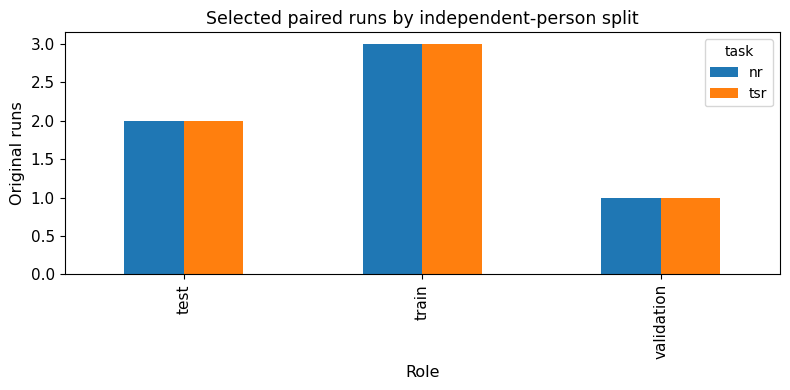

Saved Stage 01 outputs: 7


In [7]:
# ========= 06. Visualise Cohort Composition and Save Stage Evidence ==========

source.to_csv(output_dir / '01_source_manifest.csv', index=False)
roles.to_csv(output_dir / '01_split_assignments.csv', index=False)
eligibility.to_csv(output_dir / '01_source_eligibility.csv', index=False)
source_metadata.to_csv(output_dir / '01_acquisition_metadata.csv',
                       index=False)
acquired.to_csv(output_dir / '01_download_inventory.csv', index=False)
protocol = {
    'dataset_id': DATASET_ID, 'dataset_version': VERSION,
    'target': {'nr': 0, 'tsr': 1},
    'max_participants': int(MAX_PARTICIPANTS),
    'runs_per_task': int(RUNS_PER_TASK),
    'seed': SEED,
    'participant_split': roles.groupby('split').size().to_dict(),
    'window_seconds': 12., 'bin_seconds': 2.,
    'max_windows_per_run': 20, 'min_eye_fraction': 0.6,
    'final_test_policy': 'select using Validation, then score Test'
}
(output_dir / '01_protocol.json').write_text(
    json.dumps(protocol, indent=2), encoding='utf-8')
fig, ax = plt.subplots(figsize=(8, 4))
source.groupby(['split', 'task']).size().unstack(fill_value=0).plot(
    kind='bar', ax=ax)
ax.set(title='Selected paired runs by independent-person split',
       xlabel='Role', ylabel='Original runs')
fig.tight_layout()
fig.savefig(output_dir / '01_source_overview.png', dpi=170)
plt.show()
print('Saved Stage 01 outputs:', len(list(output_dir.glob('01_*'))))


**07. Interpretation and Next Dependency**

This is a source audit, not a model evaluation. The next stage
          audits temporal overlap, eye-data quality and event validity before
          accepting paired windows. Train and Test roles should remain fixed
          within the same cohort.

In [8]:
# ================== 07. Interpretation and Next Dependency ===================

assert source.participant_id.nunique() == roles.participant_id.nunique()
assert (output_dir / '01_protocol.json').exists()
print('Stage 01 source protocol is ready for alignment audit.')
print('Next: 02_eeg_gaze_alignment_and_quality.ipynb')

# ---------------------- 2. Package Stage-Owned Outputs -----------------------
download_outputs_from_colab(
    "eeg_eye_tracking_fusion/output", "01"
)


Stage 01 source protocol is ready for alignment audit.
Next: 02_eeg_gaze_alignment_and_quality.ipynb
------------------------------------------------------------------------
Notebook 01
Files packaged: 7
  + 01_acquisition_metadata.csv
  + 01_download_inventory.csv
  + 01_protocol.json
  + 01_source_eligibility.csv
  + 01_source_manifest.csv
  + 01_source_overview.png
  + 01_split_assignments.csv
Download ZIP from Colab Contents: /content/eeg_eye_tracking_fusion_Notebook_01_Outputs.zip
